## Домашка 2
<h4><em>«Одно Кольцо, чтоб править всеми,<br>
Одно Кольцо, чтоб всех найти,<br>
Одно Кольцо, чтоб собрать всех в тени<br>
И заковать их всех во Тьме»</em><br>
— <em>Властелин колец</em>
</h4>

Эта домашка про приоритизацию метрик. За неё можно получить максимум 12 баллов. 

**Дедлайны**   
Мягкий дедлайн: 27.09.2026 23:59 по МСК.   
Жесткий дедлайн: 04.10.2026 23:59 по МСК.

Штраф за сдачу после мягкого дедлайна: –20% от набранного балла.
После жесткого дедлайна работы не принимаются.

**Правила сдачи**  
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание анулируется у всех студентов, вне зависимости от того, кто у кого списал.

**Использование ИИ**

- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета. 
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например hw_2). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3. 

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.

Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/hw_2_data.zip)

In [1]:
import pandas as pd
from datetime import datetime, timedelta
import matplotlib.pyplot as plt

### Warm up

#### 1. Game dev — 2 балла
У вас есть данные о событиях в мобильной игре. Рассчитайте и визуализируйте:
- User Stickiness — отношение DAU к MAU (MAU рассчитывайте скользящим окном 30 дней для каждой даты только для полного окна)
- ARPDAU
- Paying Share — доля платящих пользователей
- Sessions per User — среднее число сессий на пользователя
- Daily Play Time — среднее время, проводимое пользователем в игре в день (рассчитываем как общее время в приложении)
- Avg Attempts per Session — среднее число попыток на сессию

*Смотрим на подневную динамику

In [2]:
df_game = pd.read_csv('data/hw_2_gamedev.csv', index_col=0)
df_game.head()

,session_id,user,date,revenue,attempts,session_length_sec
0,24590322,k0xevcHJ,2022-11-02,NaN,2.0,263
1,24590323,fMaLiagr,2022-11-02,NaN,10.0,953
2,24590324,0EXv0Q2V,2022-11-02,NaN,6.0,630
3,24590325,nY32SwuK,2022-11-02,NaN,9.0,1262
4,24590326,3KZkImTN,2022-11-02,NaN,16.0,2871


Описание данных (уникальный ключ session_id)

- session_id — уникальный идентификатор сессии
- user — уникальный идентификатор юзера
- date — дата 
- revenue — суммарная выручка на сессию
- attempts — число попыток на сессию
- session_length_sec — длина сессии в секундах

## Расчёты ъъъъъъ

In [3]:
# your code is here
import numpy as np
df_game['date'] = pd.to_datetime(df_game['date'])
daily = df_game.groupby('date').agg(
    dau=('user', 'nunique'),
    sessions=('session_id', 'nunique'),
    revenue=('revenue', 'sum'),
    play_time=('session_length_sec', 'sum'),
    attempts=('attempts', 'sum')
)
mau_list = []
for i in range(len(daily)):
    if i < 29:
        mau_list.append(np.nan)
    else:
        start = daily.index[i - 29]
        end = daily.index[i]
        mau = df_game[(df_game['date'] >= start) & (df_game['date'] <= end)]['user'].nunique()
        mau_list.append(mau)
daily['mau'] = mau_list
daily['stickiness'] = daily['dau'] / daily['mau']
daily['arpdau'] = daily['revenue'] / daily['dau']
paying = df_game[df_game['revenue'].notna()].groupby('date')['user'].nunique()
total = df_game.groupby('date')['user'].nunique()
daily['paying_share'] = paying / total
daily['sessions_per_user'] = daily['sessions'] / daily['dau']
daily['play_time_per_user'] = daily['play_time'] / daily['dau']
daily['attempts_per_session'] = daily['attempts'] / daily['sessions']
print(daily[['dau', 'mau', 'stickiness', 'arpdau', 'paying_share',
             'sessions_per_user', 'play_time_per_user', 'attempts_per_session']].head(40))

              dau       mau  stickiness    arpdau  paying_share  \
date                                                              
2022-11-02  18710       NaN         NaN  0.019312      0.001122   
2022-11-03  48669       NaN         NaN  0.063400      0.002856   
2022-11-04  60913       NaN         NaN  0.081525      0.004597   
2022-11-05  77372       NaN         NaN  0.218149      0.005570   
2022-11-06  90436       NaN         NaN  0.134531      0.006922   
2022-11-07  55711       NaN         NaN  0.284084      0.011237   
2022-11-08  47593       NaN         NaN  0.192011      0.012901   
2022-11-09  42971       NaN         NaN  0.387785      0.013428   
2022-11-10  38999       NaN         NaN  0.281799      0.015359   
2022-11-11  37635       NaN         NaN  0.318196      0.017112   
2022-11-12  35913       NaN         NaN  0.294015      0.017236   
2022-11-13  34326       NaN         NaN  0.304416      0.018237   
2022-11-14  30850       NaN         NaN  0.295213      0.01724

## Визуал, а и изация 

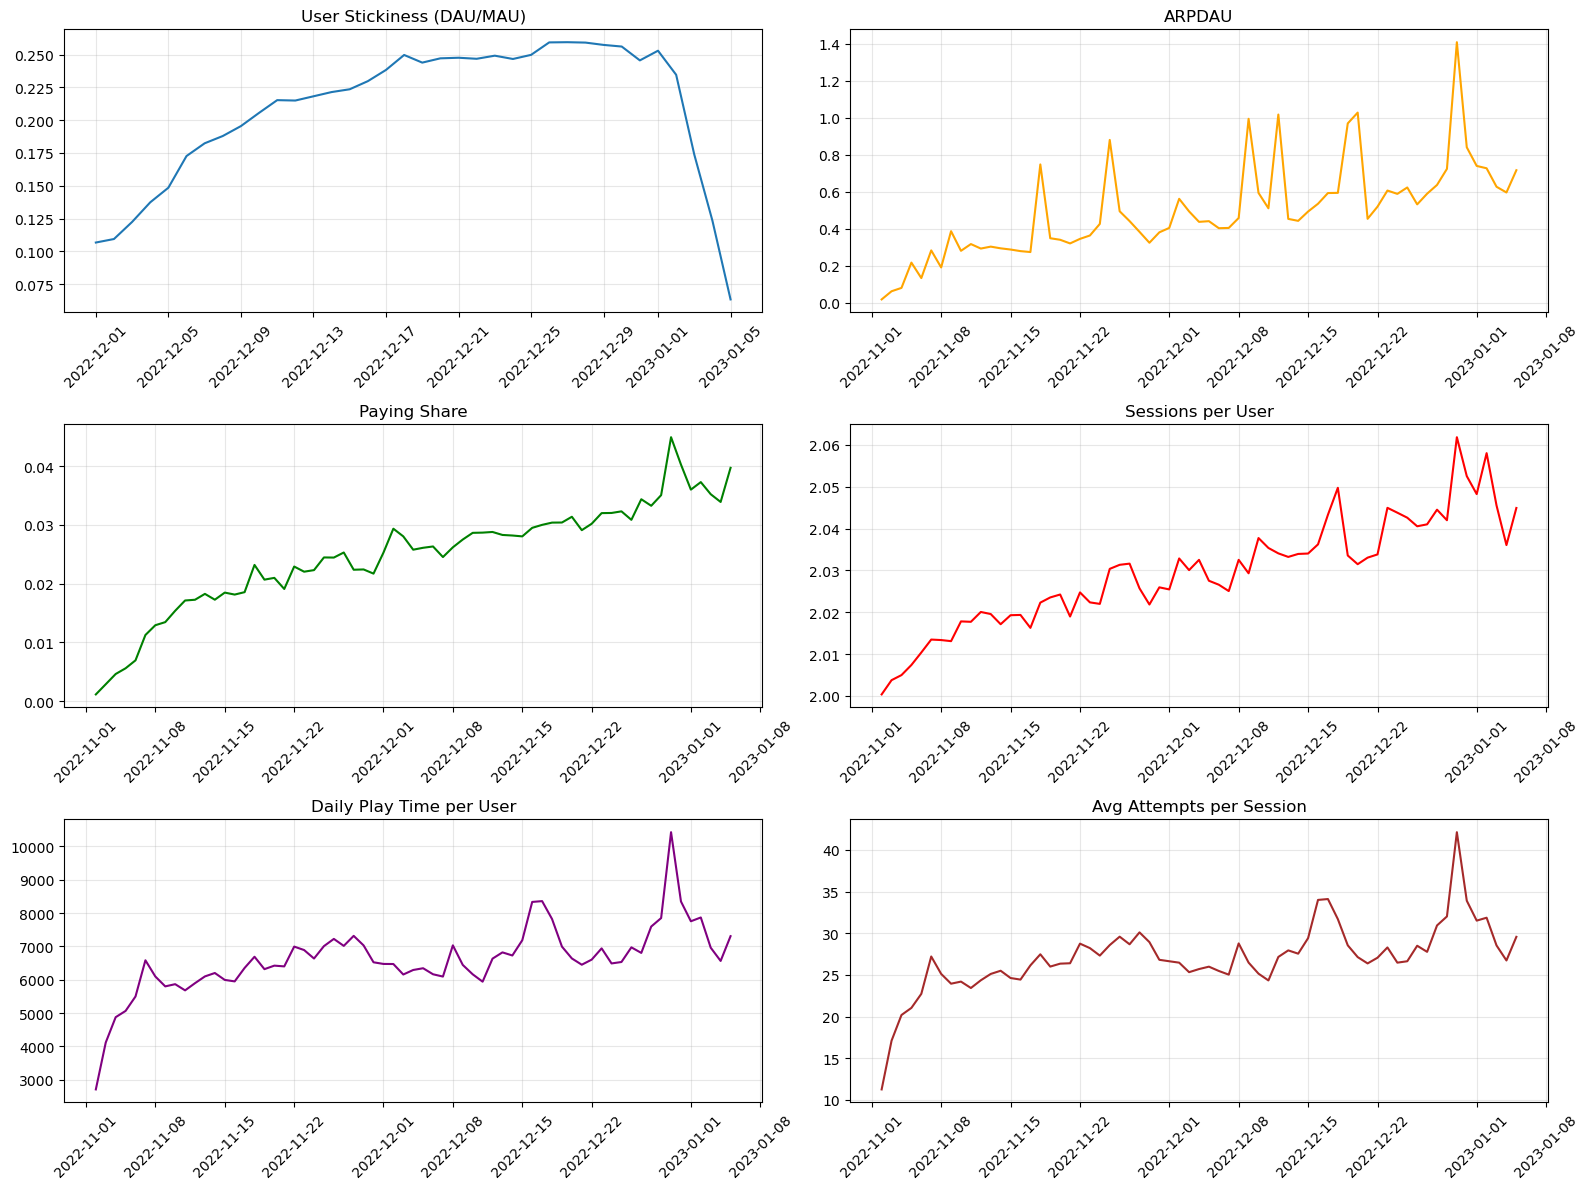

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
axes[0, 0].plot(daily.index, daily['stickiness'])
axes[0, 0].set_title('User Stickiness (DAU/MAU)')
axes[0, 1].plot(daily.index, daily['arpdau'], color='orange')
axes[0, 1].set_title('ARPDAU')
axes[1, 0].plot(daily.index, daily['paying_share'], color='green')
axes[1, 0].set_title('Paying Share')
axes[1, 1].plot(daily.index, daily['sessions_per_user'], color='red')
axes[1, 1].set_title('Sessions per User')
axes[2, 0].plot(daily.index, daily['play_time_per_user'], color='purple')
axes[2, 0].set_title('Daily Play Time per User')
axes[2, 1].plot(daily.index, daily['attempts_per_session'], color='brown')
axes[2, 1].set_title('Avg Attempts per Session')
for ax in axes.flatten():
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## А выводы не просили, я жадный!!!

#### 2. Ride hailing  — 2 балла
У вас есть данные из приложения такси. Рассчитайте и визуализируйте:
- Ride Completion Rate — CR из заказа в завершенную поездку
- Acceptance Rate — доля заказов, принятых водителем (считаем, что приняты все заказы, кроме заказов со статусом 'No Driver Found')
- Cancellation Rate — доля отмененных заказов
- Rides per Driver — среднее число поездок на водителя
- Avg Ride Check — средний чек поездки
- Отношение RTA к ETA (что измеряет эта метрика?)

*Смотрим на подневную динамику

In [5]:
df_rh = pd.read_csv('data/hw_2_taxi.csv')

In [6]:
df_rh.head()

,date,time,order_uid,order_status,passenger_id,vehicle_type,pickup_location,drop_location,ETA,RTA,...,reason_for_cancelling_by_customer,cancelled_rides_by_driver,driver_cancellation_reason,incomplete_rides,incomplete_rides_reason,fare,ride_distance,driver_ratings,customer_rating,payment_method
0,2024-01-01,00:19:34,2a11faf27f77eae8,Completed,CID8362794,Bike,Udyog Vihar,Ambience Mall,9.0,10.8,...,NaN,NaN,NaN,NaN,NaN,99.0,37.98,4.8,4.8,Cash
1,2024-01-01,01:35:18,33ed1f6bad78bdc8,Completed,CID8300238,Go Mini,Basai Dhankot,Madipur,6.0,8.5,...,NaN,NaN,NaN,NaN,NaN,114.0,39.29,4.2,4.1,Uber Wallet
2,2024-01-01,01:37:50,e2fc1fc520e93b85,Cancelled by Driver,CID2030746,Go Sedan,Tughlakabad,Greater Kailash,6.0,7.4,...,NaN,1.0,More than permitted people in there,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-01-01,01:48:03,a130fd507acf7804,Cancelled by Driver,CID3231181,Auto,Palam Vihar,Kherki Daula Toll,5.0,NaN,...,NaN,1.0,Personal & Car related issues,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024-01-01,01:49:56,cae2db8689a422fa,Cancelled by Driver,CID3381661,Go Sedan,Narsinghpur,Pulbangash,3.0,6.2,...,NaN,1.0,More than permitted people in there,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Описание данных (уникальный ключ order_uid)

- date — дата создания заказа
- time — время создания заказа
- order_uid — уникальный идентификатор заказа
- order_status — статус заказа
- passenger_id — уникальный идентификатор пассажира
- vehicle_type — тип транспорта 
- pickup_location — место отправления
- drop_location — место назначения
- ETA — прогнозное время прибытия водителя на место отправления (estimated time of arrival)
- RTA — реальное время прибытия водителя на место отправления (real time of arrival)
- driver_id — уникальный идентификатор водителя
- cancelled_rides_by_customer — флаг отмены поездки пассажиром
- reason_for_cancelling_by_customer — причина отмены поездки пассажиром
- cancelled_rides_by_driver — флаг отмены поездки водителем
- driver_cancellation_reason — причина отмены поездки водителем
- incomplete_rides — флаг незавершенной поездки
- incomplete_rides_reason — причина незавершенной поездки
- fare — цена поездки
- ride_distance – расстояние поездки
- driver_ratings — рейтинг водителя
- customer_rating — рейтинг пассажира
- payment_method – способ оплаты

## Официант, расcчитайте нас, пожалуйста

In [7]:
# your code is here
df_rh['date'] = pd.to_datetime(df_rh['date'])
daily = df_rh.groupby('date').agg(
    total_orders=('order_uid', 'count'),
    completed=('order_status', lambda x: (x == 'Completed').sum()),
    cancelled=('order_status', lambda x: x.str.contains('Cancelled').sum()),
    no_driver=('order_status', lambda x: (x == 'No Driver Found').sum()),
    avg_fare=('fare', 'mean'),
    avg_rta_eta=('RTA', lambda x: (x / df_rh.loc[x.index, 'ETA']).mean())
)
daily['completion_rate'] = daily['completed'] / daily['total_orders']
daily['acceptance_rate'] = (daily['total_orders'] - daily['no_driver']) / daily['total_orders']
daily['cancellation_rate'] = daily['cancelled'] / daily['total_orders']
drivers = df_rh.groupby('date')['driver_id'].nunique()
rides_per_driver = daily['completed'] / drivers
daily['rides_per_driver'] = rides_per_driver
print(daily.head())

            total_orders  completed  cancelled  no_driver    avg_fare  \
date                                                                    
2024-01-01           414        251        119         23  456.091912   
2024-01-02           389        240         99         32  439.639535   
2024-01-03           384        245         95         20  434.877323   
2024-01-04           414        254        104         29  416.530249   
2024-01-05           416        257        100         34  474.085106   

            avg_rta_eta  completion_rate  acceptance_rate  cancellation_rate  \
date                                                                           
2024-01-01     1.324660         0.606280         0.944444           0.287440   
2024-01-02     1.354388         0.616967         0.917738           0.254499   
2024-01-03     1.330524         0.638021         0.947917           0.247396   
2024-01-04     1.334296         0.613527         0.929952           0.251208   
2024-01-

## В И ЗУАЛИЗАЦИЯ (бедная и.....)

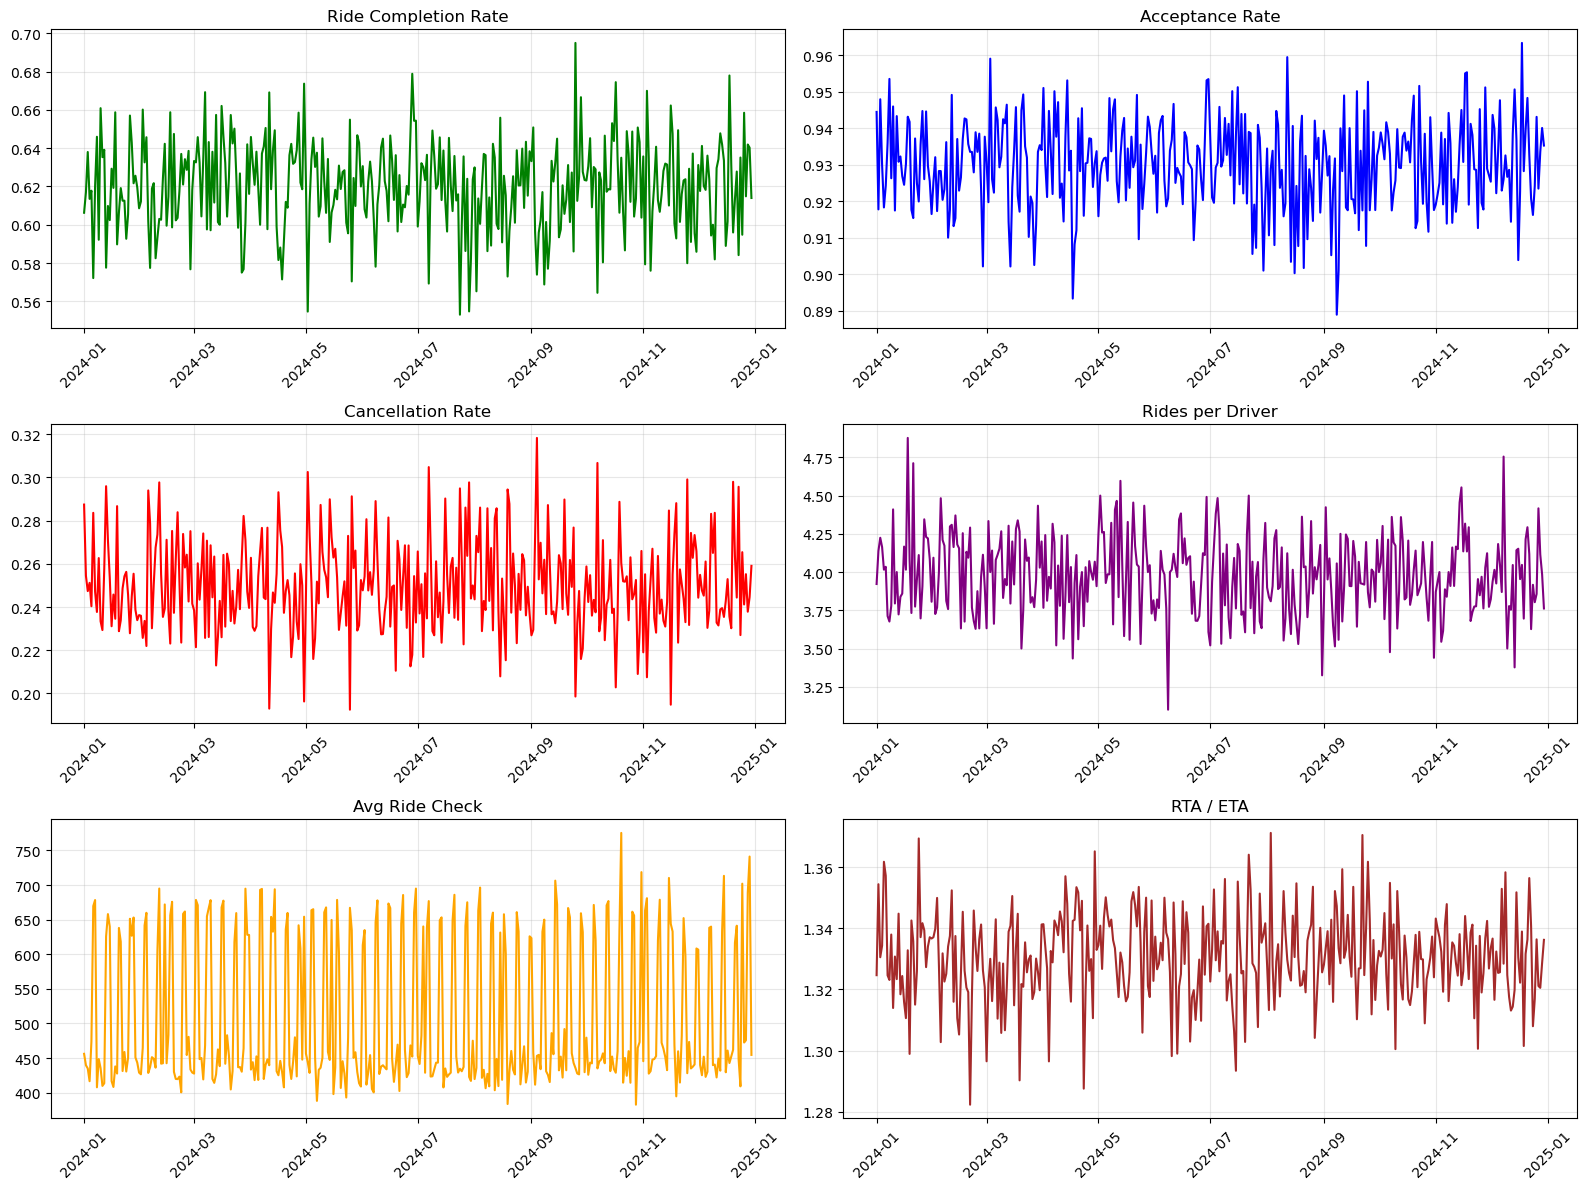

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
axes[0, 0].plot(daily.index, daily['completion_rate'], color='green')
axes[0, 0].set_title('Ride Completion Rate')
axes[0, 1].plot(daily.index, daily['acceptance_rate'], color='blue')
axes[0, 1].set_title('Acceptance Rate')
axes[1, 0].plot(daily.index, daily['cancellation_rate'], color='red')
axes[1, 0].set_title('Cancellation Rate')
axes[1, 1].plot(daily.index, daily['rides_per_driver'], color='purple')
axes[1, 1].set_title('Rides per Driver')
axes[2, 0].plot(daily.index, daily['avg_fare'], color='orange')
axes[2, 0].set_title('Avg Ride Check')
axes[2, 1].plot(daily.index, daily['avg_rta_eta'], color='brown')
axes[2, 1].set_title('RTA / ETA')
for ax in axes.flatten():
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Вывода.нет (не просили, я бак, мне надо прям в лоб тыкать, чтобы я писал вывод)))))

### Case Study. Запуск подкастов в стриминговом сервисе 🎧

**Легенда**  
Вы работаете продуктовым аналитиком в музыкальном стриминговом сервисе. Недавно в продукте запустился раздел с подкастами. Команда, отвечающая за запуск, хочет понять, стоит ли масштабировать и продвигать этот формат.

In [9]:
df_music_logs = pd.read_parquet('data/hw_2_streaming_logs.pqt')
df_music_subs = pd.read_parquet('data/hw_2_streaming_subs.pqt')

In [10]:
df_music_logs.head()

,datetime,uid,item_id,played_ratio_pct,track_length_seconds,content_type,is_first_date
0,2024-01-13 10:00:00,468300,7400764,100,225,music,0.0
1,2024-01-13 10:00:05,347600,3415205,100,250,music,0.0
2,2024-01-13 10:00:10,942900,6728180,1,270,music,0.0
3,2024-01-13 10:00:15,243500,5283544,100,195,music,0.0
4,2024-01-13 10:00:15,12700,8932363,100,245,music,0.0


In [11]:
df_music_subs.head()

,uid,start_date,end_date
0,600,2024-08-08,NaT
1,700,2024-03-29,NaT
2,800,2024-06-13,NaT
3,1100,2024-11-19,NaT
4,1400,2024-12-01,NaT


Описание данных hw_2_streaming_logs:

- datetime — дата-время взаимодействия с контентом
- uid — уникальный идентификатор пользователя
- item_id — уникальный идентификатор трека/эпизода
- played_ratio_pct — процент от длительности, который был воспроизведен
- track_length_seconds – длина трека/эпизода в секундах
- content_type — тип контента: музыка или подкаст
- is_first_date — флаг, является ли эта дата первой для пользователя в продукте

Описание данных hw_2_streaming_subs:

- uid — уникальный идентификатор пользователя
- start_date — дата начала подписки
- end_date — дата окончания подписки

#### 3. Метрики роста  — 2 балла

Рассчитайте и визуализируйте:
- DAU, MAU, WAU;
- Количество новых премиум-подписчиков (за неделю и месяц);
- Проникновение подкастов — долю юзеров, послушавших подкаст хотя бы раз (за неделю и месяц).

Сделайте выводы:
- Есть ли выраженный тренд?
- Нет ли подозрений, что с раскаткой раздела что-то могло пойти не так (изменение тренда, выраженные ступеньки)?
- Как выглядит адопшен? Можно ли предположить наличие каких-то эффектов в пользовательском взаимодействии с новым разделом?

## Раз чет, два чет, три чет, четыре чет.... (А где нечет???) 

In [12]:
# your code is here
df_music_logs['datetime'] = pd.to_datetime(df_music_logs['datetime'])
df_music_logs['date'] = df_music_logs['datetime'].dt.date
dau = df_music_logs.groupby('date')['uid'].nunique()
dates = pd.to_datetime(sorted(df_music_logs['date'].unique()))
wau_list = []
mau_list = []
for d in dates:
    start_7 = d - pd.Timedelta(days=6)
    start_30 = d - pd.Timedelta(days=29)
    wau = df_music_logs[(df_music_logs['datetime'] >= start_7) & 
                        (df_music_logs['datetime'] < d + pd.Timedelta(days=1))]['uid'].nunique()
    mau = df_music_logs[(df_music_logs['datetime'] >= start_30) & 
                        (df_music_logs['datetime'] < d + pd.Timedelta(days=1))]['uid'].nunique()
    wau_list.append(wau if d >= dates[6] else np.nan)
    mau_list.append(mau if d >= dates[29] else np.nan)
growth = pd.DataFrame({
    'dau': dau.values,
    'wau': wau_list,
    'mau': mau_list
}, index=dates)
print(growth.head(40))

             dau     wau     mau
2024-01-13  1985     NaN     NaN
2024-01-14  2547     NaN     NaN
2024-01-15  2342     NaN     NaN
2024-01-16  2471     NaN     NaN
2024-01-17  2549     NaN     NaN
2024-01-18  2568     NaN     NaN
2024-01-19  2569  4095.0     NaN
2024-01-20  2585  4156.0     NaN
2024-01-21  2644  4164.0     NaN
2024-01-22  2387  4153.0     NaN
2024-01-23  2547  4152.0     NaN
2024-01-24  2619  4181.0     NaN
2024-01-25  2656  4220.0     NaN
2024-01-26  2700  4222.0     NaN
2024-01-27  2711  4229.0     NaN
2024-01-28  2712  4253.0     NaN
2024-01-29  2472  4278.0     NaN
2024-01-30  2621  4289.0     NaN
2024-01-31  2671  4287.0     NaN
2024-02-01  2724  4316.0     NaN
2024-02-02  2740  4317.0     NaN
2024-02-03  2796  4323.0     NaN
2024-02-04  2733  4319.0     NaN
2024-02-05  2504  4312.0     NaN
2024-02-06  2640  4325.0     NaN
2024-02-07  2662  4327.0     NaN
2024-02-08  2703  4329.0     NaN
2024-02-09  2742  4343.0     NaN
2024-02-10  2854  4357.0     NaN
2024-02-11

In [13]:
df_music_subs['start_date'] = pd.to_datetime(df_music_subs['start_date'])
subs_weekly = df_music_subs.set_index('start_date').resample('W')['uid'].count()
subs_monthly = df_music_subs.set_index('start_date').resample('M')['uid'].count()
print("Новые подписчики по неделям:")
print(subs_weekly.head(10))
print("Новые подписчики по месяцам:")
print(subs_monthly)

Новые подписчики по неделям:
start_date
2024-01-14     9
2024-01-21    49
2024-01-28    63
2024-02-04    42
2024-02-11    57
2024-02-18    54
2024-02-25    67
2024-03-03    65
2024-03-10    62
2024-03-17    59
Freq: W-SUN, Name: uid, dtype: int64
Новые подписчики по месяцам:
start_date
2024-01-31    147
2024-02-29    232
2024-03-31    272
2024-04-30    290
2024-05-31    300
2024-06-30    326
2024-07-31    311
2024-08-31    344
2024-09-30    322
2024-10-31    355
2024-11-30    349
2024-12-31    355
Freq: ME, Name: uid, dtype: int64


C:\Users\Михаил\AppData\Local\Temp\ipykernel_12036\3100354346.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  subs_monthly = df_music_subs.set_index('start_date').resample('M')['uid'].count()


In [14]:
podcasts = df_music_logs[df_music_logs['content_type'] == 'podcast']
total_users = df_music_logs.groupby(pd.Grouper(key='datetime', freq='W'))['uid'].nunique()
podcast_users = podcasts.groupby(pd.Grouper(key='datetime', freq='W'))['uid'].nunique()
penetration_weekly = podcast_users / total_users
total_users_m = df_music_logs.groupby(pd.Grouper(key='datetime', freq='M'))['uid'].nunique()
podcast_users_m = podcasts.groupby(pd.Grouper(key='datetime', freq='M'))['uid'].nunique()
penetration_monthly = podcast_users_m / total_users_m
print("Проникновение подкастов по неделям:")
print(penetration_weekly)
print("Проникновение подкастов по месяцам:")
print(penetration_monthly)

C:\Users\Михаил\AppData\Local\Temp\ipykernel_12036\1893784679.py:5: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  total_users_m = df_music_logs.groupby(pd.Grouper(key='datetime', freq='M'))['uid'].nunique()


Проникновение подкастов по неделям:
datetime
2024-01-14         NaN
2024-01-21         NaN
2024-01-28         NaN
2024-02-04         NaN
2024-02-11         NaN
2024-02-18         NaN
2024-02-25         NaN
2024-03-03         NaN
2024-03-10         NaN
2024-03-17         NaN
2024-03-24         NaN
2024-03-31         NaN
2024-04-07         NaN
2024-04-14         NaN
2024-04-21         NaN
2024-04-28         NaN
2024-05-05         NaN
2024-05-12         NaN
2024-05-19         NaN
2024-05-26         NaN
2024-06-02         NaN
2024-06-09         NaN
2024-06-16         NaN
2024-06-23         NaN
2024-06-30         NaN
2024-07-07         NaN
2024-07-14         NaN
2024-07-21         NaN
2024-07-28         NaN
2024-08-04         NaN
2024-08-11         NaN
2024-08-18         NaN
2024-08-25         NaN
2024-09-01    0.028518
2024-09-08    0.122536
2024-09-15    0.123400
2024-09-22    0.142021
2024-09-29    0.136037
2024-10-06    0.125406
2024-10-13    0.124380
2024-10-20    0.133163
2024-10-27  

C:\Users\Михаил\AppData\Local\Temp\ipykernel_12036\1893784679.py:6: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  podcast_users_m = podcasts.groupby(pd.Grouper(key='datetime', freq='M'))['uid'].nunique()


## Визу, а Лиза Ция (я не дал бы визу человеку с ФИО Ция Лиза) 

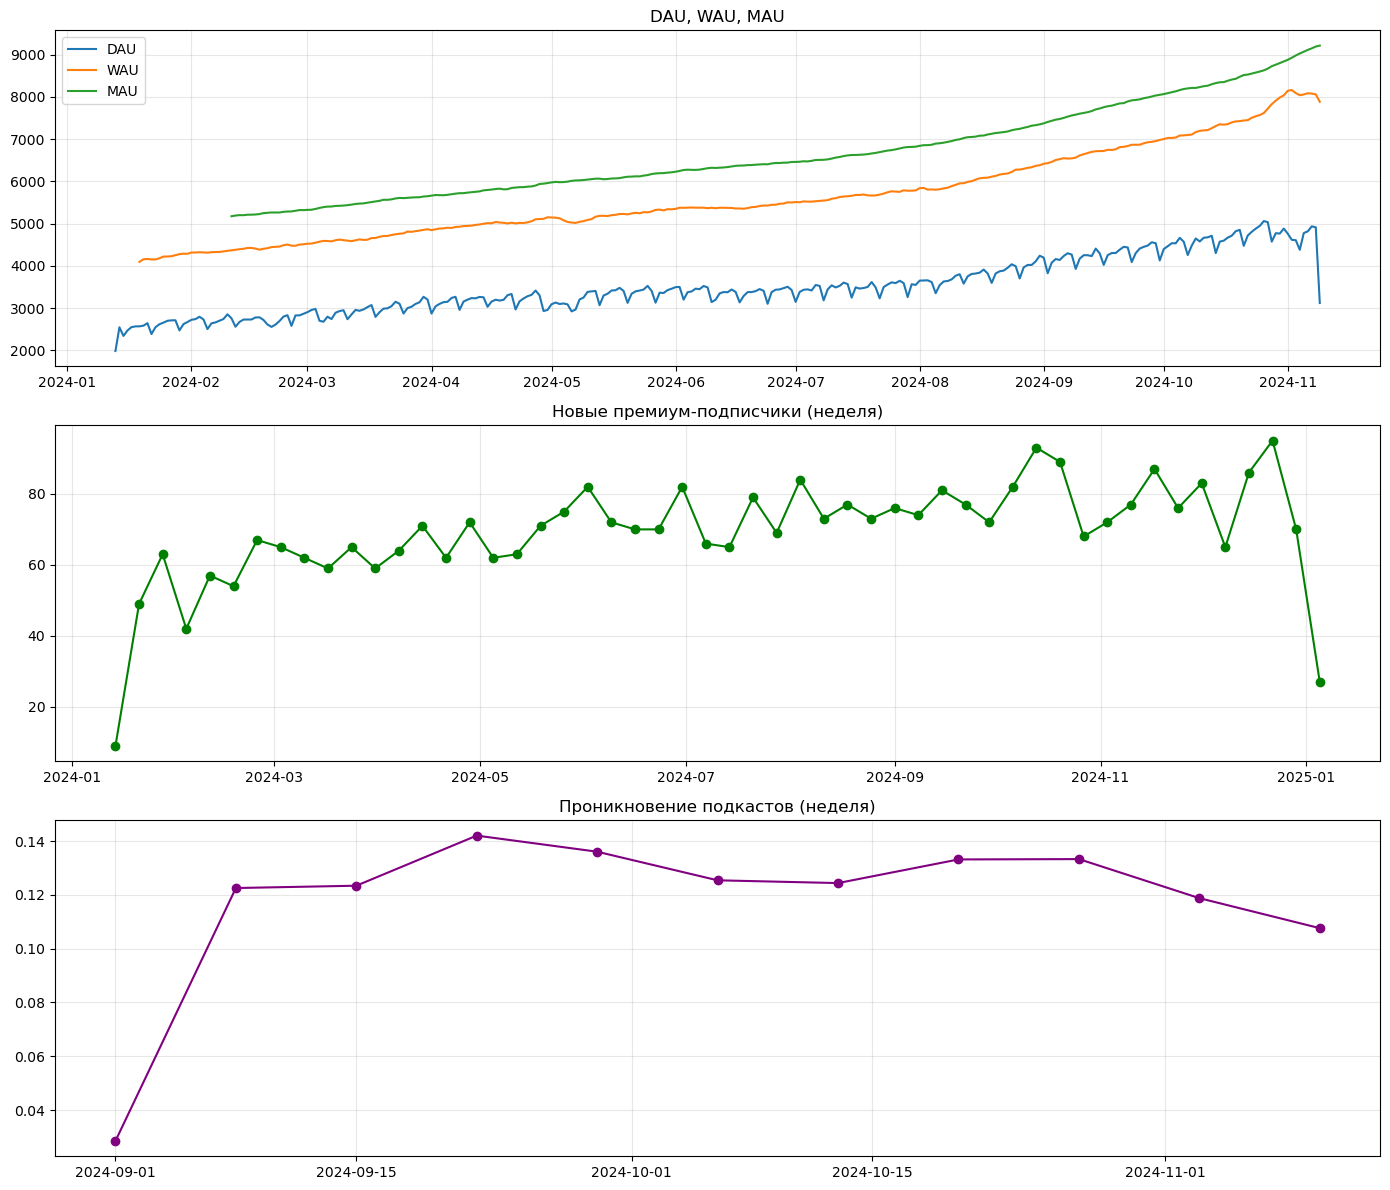

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
axes[0].plot(growth.index, growth['dau'], label='DAU')
axes[0].plot(growth.index, growth['wau'], label='WAU')
axes[0].plot(growth.index, growth['mau'], label='MAU')
axes[0].set_title('DAU, WAU, MAU')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[1].plot(subs_weekly.index, subs_weekly.values, marker='o', color='green')
axes[1].set_title('Новые премиум-подписчики (неделя)')
axes[1].grid(True, alpha=0.3)
axes[2].plot(penetration_weekly.index, penetration_weekly.values, marker='o', color='purple')
axes[2].set_title('Проникновение подкастов (неделя)')
axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Подловили, тут выводы нужны :(((((

# Выводы
1. Есть ли выраженный тренд?

Да, у нас имеется позитивный тренд на рост, радуйтесь, не зря батрачим. DAU вырос с 2к до 3к, но потом подупал до 2500, по этому вопросу следует провести более глубокую аналитику, ибо падение выглядет слегка аномально. MAU и WAU растут стабильно, от изначальных 5200 и 4100 соответственно, до 9100 и 7000 соответственно. Субскрайберы также стабильно растут, пугает только резкий спад платных подписок в начале 2025 года, но на 99% просто у людей закончилась годовая подписка, и в течении следующего месяца показатели вернутся назад. 

2. Нет ли подозрений, что с раскаткой раздела что-то могло пойти не так?

Подкасты появились только с сентября 2024 года, при всем уважении делать радикальные вывод за такой короткий срок - невозможно. Из предоставленных данных, можно заметить стогнацию раздела, новая аудитория не прибавляется и мы болтаемся в одном и том же диапозоне. Вариант 1. Мы инвистируеим в раздел деньги (что, имхо, бессмысленно), Вариант 2. Мы приглашаем новых гостей из различных сфер. Но опять же, все еще считаю срок ничтожным, для полной аналитики. 


3. Как выглядит адопшен?

Адопшен выглядит супер базово, быстрый взлёт с 0 до 12%, затем фиксация на взятой высоте. Вышли на плато и стабилизировались, пока покатит, выше расписаны варианты роста.

4. Можно ли предположить наличие каких-то эффектов в пользовательском взаимодействии с новым разделом?

Предположить можно, но лучше копаться глубже. Если посмотреть на показатели DAU и WAU графики с сентября стали круче, незначительно, но приятно. Советую провести A/B тест, для уточнения связи данных событий. 

#### 4. Метрики продукта (шаг 1)  — 2 балла

Рассчитайте и визуализируйте как для всех пользователей в совокупности, так и для сегментов пользователей в разрезе — сделали / не сделали взаимодействие с подкастами (грубо говоря разделяем юзеров на тех, кто слушает только музыку и тех, кто слушает еще и подкасты):
1. Среднее время прослушивания на пользователя.
2. Среднее число треков/эпизодов на пользователя (среднее число item_id). Посчитайте метрику, как от уникальных, так и от не уникальных item_id. Подумайте, что показывает каждая из них?
3. Долю премиум-подписчиков. Обратите внимание, что нам нужна активная подписка, если пользователь отписался в том же периоде, что подписался, мы больше не считаем подписку активной.

Рассчитайте и визуализируйте как по всем item_id, так и в разрезе типов контента:
- Долю дослушанных треков/эпизодов до конца. Обратите внимание, данная метрика уже не пользовательская.

Периоды — неделя и месяц. Неполные периоды нужно обрезать, если они мешают чтению графиков.   
Признак взаимодействия присвайвайте только для периода, когда оно действительно было.   
Для месячной динамики метрик по признаку взаимодействия с подкастами у вас получится всего 2 точки, такая визуализая тоже полезна, она сглаживает недельные колебания и помогает оценивать тренд в масштабе года.

Сделайте выводы:
- Есть ли выраженный тренд?
- Изменилась ли метрика после запуска подкастов?
- Отличается ли метрика сегмента, взаимодействовавшего с подкастами, от тех, кто слушал только музыку? (будьте аккуратны с выводами в этом пункте, мы не проверяем изменение на каузальность, поэтому не можем быть уверены где причина, а где следствие)
- Есть ли отличия между типами контента?

*За взаимодействие с подкастами давайте считать только прослушивание >= 30% или более 2х минут контента*

## Микро ~~займ~~ расчет

In [17]:
# your code is here
df_music_logs['datetime'] = pd.to_datetime(df_music_logs['datetime'])
df_music_logs['week'] = df_music_logs['datetime'].dt.to_period('W').dt.start_time
df_music_logs['month'] = df_music_logs['datetime'].dt.to_period('M').dt.start_time
df_music_logs['is_podcast_interaction'] = (
    (df_music_logs['content_type'] == 'podcast') &
    (
        (df_music_logs['played_ratio_pct'] >= 30) |
        (df_music_logs['track_length_seconds'] * df_music_logs['played_ratio_pct'] / 100 > 120)
    )
)

podcast_weeks = df_music_logs[df_music_logs['is_podcast_interaction']][['week', 'uid']].drop_duplicates()
podcast_weeks['segment_podcast'] = 'podcast'
df_music_logs = df_music_logs.merge(podcast_weeks, on=['week', 'uid'], how='left')
df_music_logs['segment'] = df_music_logs['segment_podcast'].fillna('music_only')
df_music_logs = df_music_logs.drop(columns=['segment_podcast'])
print(df_music_logs.groupby(['week', 'segment']).size().unstack(fill_value=0).head(40))

segment     music_only  podcast
week                           
2024-01-08      172134        0
2024-01-15      758878        0
2024-01-22      782144        0
2024-01-29      805035        0
2024-02-05      795805        0
2024-02-12      803429        0
2024-02-19      802399        0
2024-02-26      861975        0
2024-03-04      851971        0
2024-03-11      895744        0
2024-03-18      901344        0
2024-03-25      912442        0
2024-04-01      946857        0
2024-04-08      979223        0
2024-04-15      959708        0
2024-04-22      979067        0
2024-04-29      944602        0
2024-05-06      973589        0
2024-05-13     1018635        0
2024-05-20     1041785        0
2024-05-27     1044838        0
2024-06-03     1051159        0
2024-06-10     1038889        0
2024-06-17     1030197        0
2024-06-24     1060478        0
2024-07-01     1055175        0
2024-07-08     1097208        0
2024-07-15     1077624        0
2024-07-22     1104461        0
2024-07-

In [18]:
weekly = df_music_logs.groupby(['week', 'segment']).agg(
    users=('uid', 'nunique'),
    total_time=('track_length_seconds', 'sum'),
    items=('item_id', 'count'),
    unique_items=('item_id', 'nunique'),
    finished=('played_ratio_pct', lambda x: (x == 100).sum())
).reset_index()
weekly['time_per_user'] = weekly['total_time'] / weekly['users']
weekly['items_per_user'] = weekly['items'] / weekly['users']
weekly['unique_items_per_user'] = weekly['unique_items'] / weekly['users']
weekly['finished_ratio'] = weekly['finished'] / weekly['items']
print(weekly.pivot(index='week', columns='segment', values='time_per_user').head(20))

segment       music_only  podcast
week                             
2024-01-08  11817.978473      NaN
2024-01-15  37401.681076      NaN
2024-01-22  38017.926170      NaN
2024-01-29  38526.638111      NaN
2024-02-05  37638.593178      NaN
2024-02-12  37875.044480      NaN
2024-02-19  36693.209767      NaN
2024-02-26  38977.641240      NaN
2024-03-04  38016.245119      NaN
2024-03-11  40272.842275      NaN
2024-03-18  39430.207940      NaN
2024-03-25  38992.830731      NaN
2024-04-01  39945.451128      NaN
2024-04-08  40419.632780      NaN
2024-04-15  39422.596575      NaN
2024-04-22  39669.237471      NaN
2024-04-29  38697.569444      NaN
2024-05-06  38794.940937      NaN
2024-05-13  40013.938612      NaN
2024-05-20  40401.285228      NaN


## Визу Али за Ция (идеи кончаются, но визу за другого человека получать нельзя!)

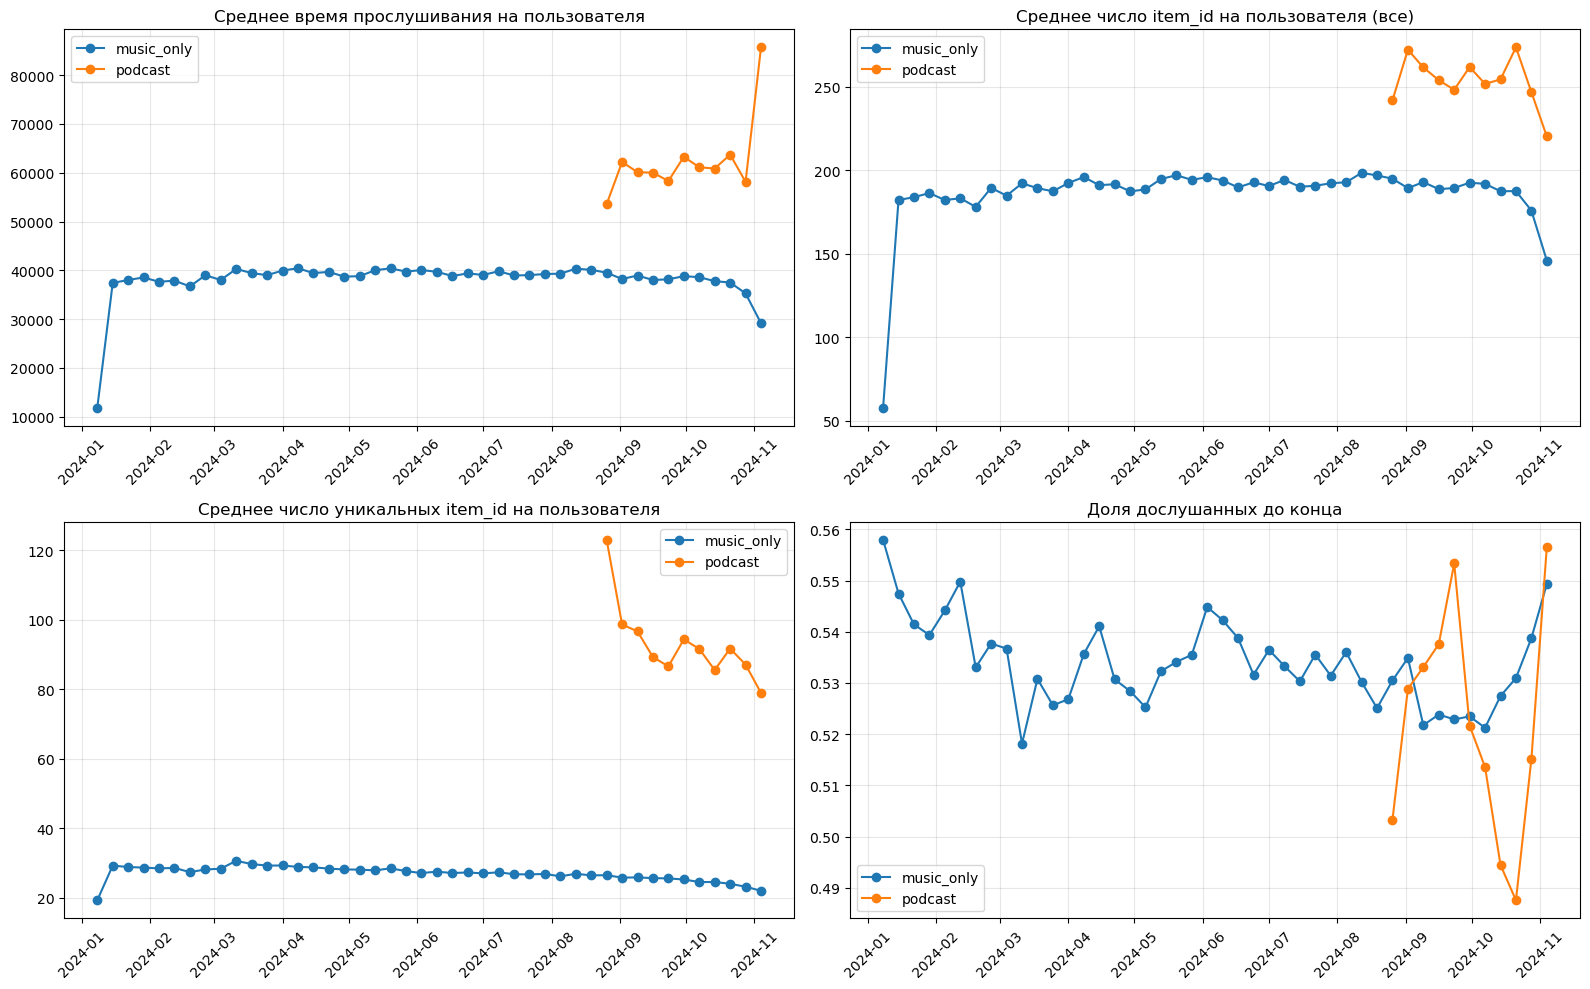

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for seg in ['music_only', 'podcast']:
    seg_data = weekly[weekly['segment'] == seg]
    axes[0, 0].plot(seg_data['week'], seg_data['time_per_user'], marker='o', label=seg)
    axes[0, 1].plot(seg_data['week'], seg_data['items_per_user'], marker='o', label=seg)
    axes[1, 0].plot(seg_data['week'], seg_data['unique_items_per_user'], marker='o', label=seg)
    axes[1, 1].plot(seg_data['week'], seg_data['finished_ratio'], marker='o', label=seg)

axes[0, 0].set_title('Среднее время прослушивания на пользователя')
axes[0, 1].set_title('Среднее число item_id на пользователя (все)')
axes[1, 0].set_title('Среднее число уникальных item_id на пользователя')
axes[1, 1].set_title('Доля дослушанных до конца')
for ax in axes.flatten():
    ax.tick_params(axis='x', rotation=45)
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

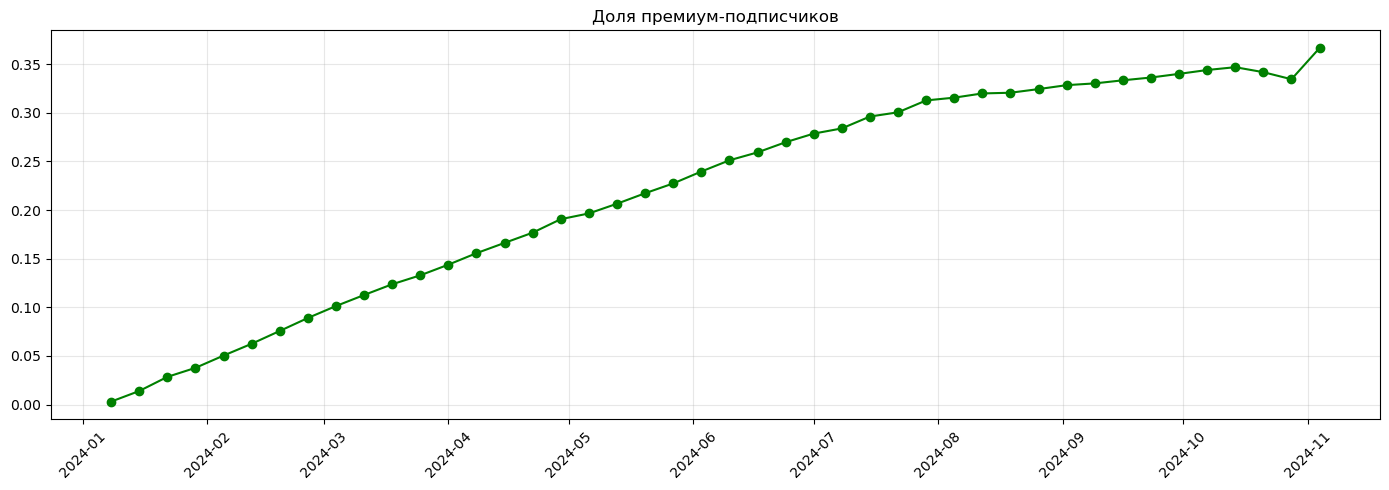

         week  active_subs  total_users  premium_share
0  2024-01-08            9         2973       0.003027
1  2024-01-15           58         4164       0.013929
2  2024-01-22          121         4253       0.028451
3  2024-01-29          163         4319       0.037740
4  2024-02-05          220         4368       0.050366
5  2024-02-12          274         4384       0.062500
6  2024-02-19          341         4505       0.075694
7  2024-02-26          405         4549       0.089031
8  2024-03-04          467         4610       0.101302
9  2024-03-11          525         4660       0.112661
10 2024-03-18          589         4761       0.123714
11 2024-03-25          647         4868       0.132909
12 2024-04-01          708         4921       0.143873
13 2024-04-08          778         4997       0.155693
14 2024-04-15          835         5022       0.166268
15 2024-04-22          903         5108       0.176782
16 2024-04-29          961         5040       0.190675
17 2024-05

In [20]:
df_music_subs['start_date'] = pd.to_datetime(df_music_subs['start_date'])
df_music_subs['end_date'] = pd.to_datetime(df_music_subs['end_date'], errors='coerce')
def is_active(sub_row, week_start, week_end):
    if sub_row['start_date'] > week_end:
        return False
    if pd.notna(sub_row['end_date']) and sub_row['end_date'] <= sub_row['start_date']:
        return False
    if pd.notna(sub_row['end_date']) and sub_row['end_date'] < week_start:
        return False
    return True
weeks = df_music_logs['week'].unique()
active_counts = {}
for w in weeks:
    w_end = w + pd.Timedelta(days=6)
    active = df_music_subs[(df_music_subs['start_date'] <= w_end) & 
                           ((df_music_subs['end_date'].isna()) | (df_music_subs['end_date'] >= w))]['uid'].nunique()
    active_counts[w] = active
active_df = pd.DataFrame(list(active_counts.items()), columns=['week', 'active_subs'])
total_users_week = df_music_logs.groupby('week')['uid'].nunique().reset_index()
total_users_week.columns = ['week', 'total_users']
active_df = active_df.merge(total_users_week, on='week')
active_df['premium_share'] = active_df['active_subs'] / active_df['total_users']
plt.figure(figsize=(14, 5))
plt.plot(active_df['week'], active_df['premium_share'], marker='o', color='green')
plt.title('Доля премиум-подписчиков')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(active_df.head(20))

## Выводы

1. Есть ли выраженный тренд?

Судить о выраженном тренде - сложно, у сегмента music_only все метрики стабильны. Подкасты еще просто слишком молодые. Объективно тренд выявить невозможно.

2. Изменилась ли метрика после запуска подкастов?

Нет.

3. Отличается ли сегмент `podcast` от `music_only`?

Да, радикально. Различное время прослушивания (55-65к сек vs 38-40к сек), отличается количество и уникальность item_id

4. Есть ли отличия между типами контента?

Существенного различия - нет, по доле дослушивания до конца отличий почти не наблюдается.

#### 5. Метрики продукта (шаг 2)  — 2 балла

Рассчитайте и визуализируйте:
1) D1, D7, D30 retention по всем пользователям. Когорты агрегируйте по неделям т.к. из-за низкого числа новичков на дневном разрезе визуализации слишком шумные.
2) D30 retention для сегментов пользователей в разрезе — сделали / не сделали взаимодействие с подкастами на промежутке до 30 дня. Когорты агрегируйте по неделям.
3) D7 retention для сегментов пользователей в разрезе — сделали / не сделали взаимодействие с подкастами на промежутке до 7 дня. Когорты агрегируйте по месяцам.

Для наглядности будет полезно нарисовать на одном графике как посегментную, так и общую динамику (для этого можете достроить D7 retention для всех пользователей с помесячной агрегацией).

Сделайте выводы: 
- Есть ли выраженный тренд?
- Изменилась ли метрика после запуска подкастов?
- Отличается ли метрика сегмента, взаимодействовавшего с подкастами, от тех, кто слушал только музыку? (будьте аккуратны с выводами в этом пункте, мы не проверяем изменение на каузальность, поэтому не можем быть уверены где причина, а где следствие)

*За взаимодействие с подкастами давайте считать только прослушивание >= 30% или более 2х минут контента*

## Бог Ра не видел счёт

In [21]:
# your code is here
df_music_logs['date'] = df_music_logs['datetime'].dt.date
first_date = df_music_logs.groupby('uid')['date'].min().reset_index()
first_date.columns = ['uid', 'first_date']
first_date['cohort_week'] = pd.to_datetime(first_date['first_date']).dt.to_period('W').dt.start_time
first_date['cohort_month'] = pd.to_datetime(first_date['first_date']).dt.to_period('M').dt.start_time
df_ret = df_music_logs.merge(first_date, on='uid')
df_ret['days_since_first'] = (pd.to_datetime(df_ret['date']) - pd.to_datetime(df_ret['first_date'])).dt.days
d1_users = set(df_ret[df_ret['days_since_first'] == 1]['uid'].unique())
d7_users = set(df_ret[df_ret['days_since_first'] == 7]['uid'].unique())
d30_users = set(df_ret[df_ret['days_since_first'] == 30]['uid'].unique())
cohorts = first_date.groupby('cohort_week')['uid'].apply(set).reset_index()
cohorts['cohort_size'] = cohorts['uid'].apply(len)
cohorts['d1'] = cohorts['uid'].apply(lambda u: len(u & d1_users) / len(u) if len(u) > 0 else np.nan)
cohorts['d7'] = cohorts['uid'].apply(lambda u: len(u & d7_users) / len(u) if len(u) > 0 else np.nan)
cohorts['d30'] = cohorts['uid'].apply(lambda u: len(u & d30_users) / len(u) if len(u) > 0 else np.nan)
print(cohorts[['cohort_week', 'cohort_size', 'd1', 'd7', 'd30']].head(30))

   cohort_week  cohort_size        d1        d7       d30
0   2024-01-08         2973  0.721157  0.696603  0.602758
1   2024-01-15         1336  0.453593  0.393713  0.370509
2   2024-01-22          400  0.375000  0.280000  0.265000
3   2024-01-29          275  0.363636  0.236364  0.210909
4   2024-02-05          191  0.371728  0.282723  0.251309
5   2024-02-12          141  0.375887  0.297872  0.269504
6   2024-02-19          158  0.360759  0.278481  0.272152
7   2024-02-26          146  0.424658  0.212329  0.294521
8   2024-03-04          130  0.400000  0.323077  0.292308
9   2024-03-11          138  0.449275  0.478261  0.384058
10  2024-03-18          128  0.492188  0.429688  0.429688
11  2024-03-25          115  0.539130  0.426087  0.295652
12  2024-04-01          105  0.476190  0.400000  0.323810
13  2024-04-08           98  0.510204  0.418367  0.377551
14  2024-04-15          100  0.530000  0.420000  0.390000
15  2024-04-22           92  0.478261  0.423913  0.467391
16  2024-04-29

In [22]:
df_music_logs['date'] = df_music_logs['datetime'].dt.date
first_date = df_music_logs.groupby('uid')['date'].min().reset_index()
first_date.columns = ['uid', 'first_date']
first_date['cohort_week'] = pd.to_datetime(first_date['first_date']).dt.to_period('W').dt.start_time
df_ret = df_music_logs.merge(first_date, on='uid')
df_ret['days_since_first'] = (pd.to_datetime(df_ret['date']) - pd.to_datetime(df_ret['first_date'])).dt.days
podcast_users = set(df_music_logs[df_music_logs['is_podcast_interaction']]['uid'].unique())
df_ret['user_segment'] = np.where(df_ret['uid'].isin(podcast_users), 'podcast', 'music_only')
d30_users = set(df_ret[df_ret['days_since_first'] == 30]['uid'].unique())
cohorts = df_ret.groupby(['cohort_week', 'user_segment'])['uid'].apply(set).reset_index()
cohorts['cohort_size'] = cohorts['uid'].apply(len)
cohorts['d30'] = cohorts['uid'].apply(lambda u: len(u & d30_users) / len(u) if len(u) > 0 else np.nan)
print(cohorts.pivot(index='cohort_week', columns='user_segment', values='d30').head(30))

user_segment  music_only   podcast
cohort_week                       
2024-01-08      0.571287  0.669465
2024-01-15      0.338415  0.460227
2024-01-22      0.253870  0.311688
2024-01-29      0.214286  0.196078
2024-02-05      0.240000  0.292683
2024-02-12      0.282051  0.208333
2024-02-19      0.220472  0.483871
2024-02-26      0.290323  0.318182
2024-03-04      0.259615  0.423077
2024-03-11      0.367925  0.437500
2024-03-18      0.407407  0.550000
2024-03-25      0.313953  0.241379
2024-04-01      0.256410  0.518519
2024-04-08      0.346154  0.500000
2024-04-15      0.400000  0.350000
2024-04-22      0.426667  0.647059
2024-04-29      0.400000  0.541667
2024-05-06      0.338710  0.500000
2024-05-13      0.450000  0.571429
2024-05-20      0.391892  0.315789
2024-05-27      0.294118  0.545455
2024-06-03      0.409091  0.380952
2024-06-10      0.527273  0.312500
2024-06-17      0.391304  0.454545
2024-06-24      0.396552  0.523810
2024-07-01      0.361111  0.529412
2024-07-08      0.39

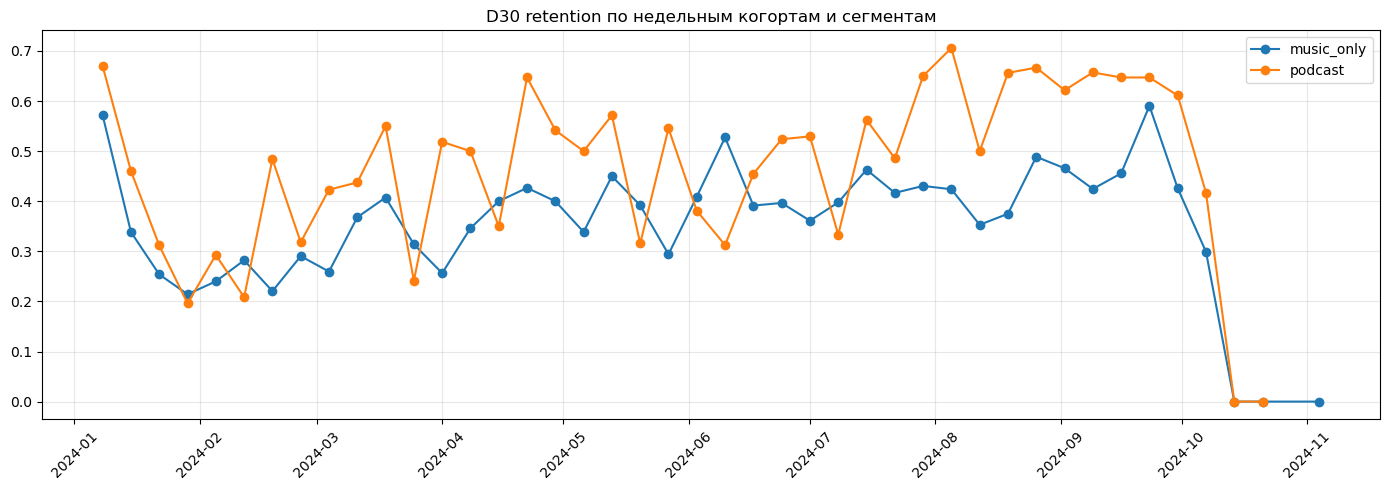

In [23]:
pivot_d30 = cohorts.pivot(index='cohort_week', columns='user_segment', values='d30')
plt.figure(figsize=(14, 5))
for seg in pivot_d30.columns:
    plt.plot(pivot_d30.index, pivot_d30[seg], marker='o', label=seg)
plt.title('D30 retention по недельным когортам и сегментам')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

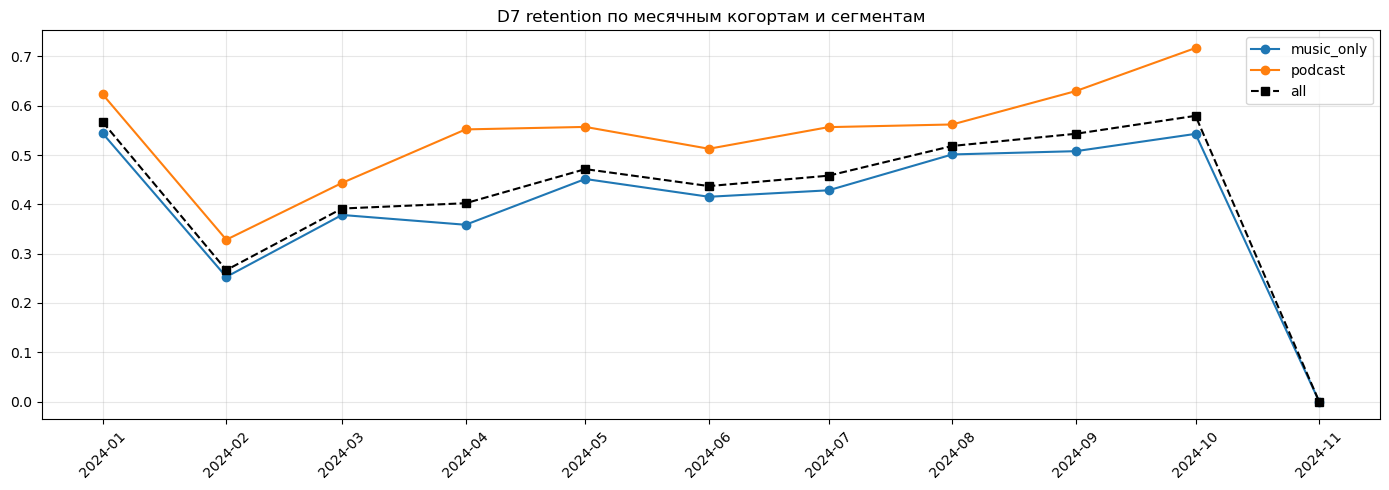

user_segment  music_only   podcast
cohort_month                      
2024-01-01      0.544019  0.623137
2024-02-01      0.252931  0.328358
2024-03-01      0.378556  0.443478
2024-04-01      0.358663  0.552083
2024-05-01      0.451505  0.557143
2024-06-01      0.415441  0.512821
2024-07-01      0.428571  0.556701
2024-08-01      0.501292  0.562092
2024-09-01      0.507937  0.629870
2024-10-01      0.543011  0.717172
2024-11-01      0.000000       NaN


In [24]:
first_date['cohort_month'] = pd.to_datetime(first_date['first_date']).dt.to_period('M').dt.start_time
df_ret = df_music_logs.merge(first_date, on='uid')
df_ret['days_since_first'] = (pd.to_datetime(df_ret['date']) - pd.to_datetime(df_ret['first_date'])).dt.days
df_ret['user_segment'] = np.where(df_ret['uid'].isin(podcast_users), 'podcast', 'music_only')
d7_users = set(df_ret[df_ret['days_since_first'] == 7]['uid'].unique())
cohorts_m = df_ret.groupby(['cohort_month', 'user_segment'])['uid'].apply(set).reset_index()
cohorts_m['cohort_size'] = cohorts_m['uid'].apply(len)
cohorts_m['d7'] = cohorts_m['uid'].apply(lambda u: len(u & d7_users) / len(u) if len(u) > 0 else np.nan)
pivot_d7 = cohorts_m.pivot(index='cohort_month', columns='user_segment', values='d7')
plt.figure(figsize=(14, 5))
for seg in pivot_d7.columns:
    plt.plot(pivot_d7.index, pivot_d7[seg], marker='o', label=seg)
all_users_m = first_date.groupby('cohort_month')['uid'].apply(set).reset_index()
all_users_m['d7'] = all_users_m['uid'].apply(lambda u: len(u & d7_users) / len(u) if len(u) > 0 else np.nan)
plt.plot(all_users_m['cohort_month'], all_users_m['d7'], marker='s', linestyle='--', color='black', label='all')
plt.title('D7 retention по месячным когортам и сегментам')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(pivot_d7)

## В ы было много воды (идеи закончились, пошли баяны)

1. Есть ли выраженный тренд?

Тут имеется, слабовосходящий тренд  метрик D7; D30 жестко колеблится, тренда там не наблюдается.

2. Изменилась ли метрика после запуска подкастов?

После запуска подкастов ретеншен не упал, но и не взлетел, D7 у подкастеров даже немного вырос, что является несомненно позитивным моментиком. 

3. Отличается ли сегмент `podcast` от `music_only`

Радикально

#### 6. Приоритизация метрик  — 2 балла

Составьте список всех метрик, которые были рассчитаны выше (не забудьте, что показатель, рассчитанный в разрезе сегмента — это отдельная метрика). Для простоты давайте ориентироваться только на недельную агрегацию.

1. Присвойте метрикам приоритеты P0-P3 по принципу (в этом пункте стройте приоритизацию на уровне всей компании):
   -  P0 — бизнес результат;
   -  P1 — метрики продукта, напрямую аффектящие бизнес-результат (retention, product as a habit);
   -  P2 — метрики, отражающие взаимодействие пользователя с продуктом (user experience, user engagement) / таргет-метрики отдельных команд продукта;
   -  P3 — метрики стримов / опыт пользователя в рамках работы отдельных команд.
2. Пересоберите приоритеты только для команды подкастов, если цель развития подкастов — рост пользователей с подпиской. Обратите внимание, что вам не нужно отказываться от метрик, рассчитанных по всем пользователям (без сегментов) или для сегмента Music (полезно понимать, не каннибализируем ли мы основной тип контента). Скорее всего приоритеты изменятся только для посегментных метрик.
4. Представьте, что цель внедрения подкастов поменялась — теперь команда в первую очередь хочет задрайвить вовлеченность в продукт. Пересоберите приоритеты при необходимости (в данном пункте могут измениться приоритеты для метрик, рассчитанных по всем пользователям).

Для каждого из пунктов дайте краткое обоснование, почему вы присвоили приоритеты именно так.

Я устал, сори, я лентяй, что капец :( 